In [20]:
from google.colab import files
uploaded = files.upload()

Saving netflix_cleaned.csv to netflix_cleaned (1).csv


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned Netflix dataset
df = pd.read_csv("netflix_cleaned.csv")

# Display basic information
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nContent type counts:")
print(df["type"].value_counts())


Dataset shape: (8807, 14)

First five rows:
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water          Unknown   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans          Unknown   
4      s5  TV Show           Kota Factory          Unknown   

                                                cast        country  \
0                                            Unknown  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...        Unknown   
3                                            Unknown        Unknown   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

   date_added  release_year rating   duration  \
0  2021-09-25          2020  PG-13     90 min   
1  2021-09-24          2021  TV-MA  2 Seasons   
2  2021-0

###Count and compare Movies and TV Shows

Number of Movies: 6131
Number of TV Shows: 2676

Percentage distribution:
type
Movie      69.62
TV Show    30.38
Name: count, dtype: float64


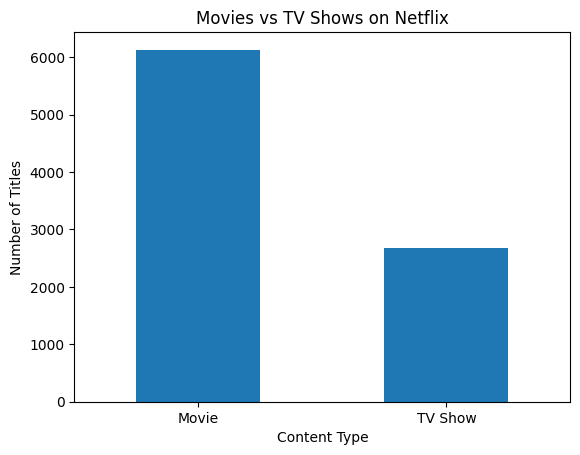

In [ ]:

# Count Movies and TV Shows
type_counts = df["type"].value_counts()

print("Number of Movies:", type_counts.get("Movie", 0))
print("Number of TV Shows:", type_counts.get("TV Show", 0))

# Calculate percentage
print("\nPercentage distribution:")
print((type_counts / len(df) * 100).round(2))

# Create a bar chart
type_counts.plot(kind="bar")

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.show()


##Histogram of movie durations

Average movie duration: 99.56 minutes
Shortest movie: 3.0 minutes
Longest movie: 312.0 minutes


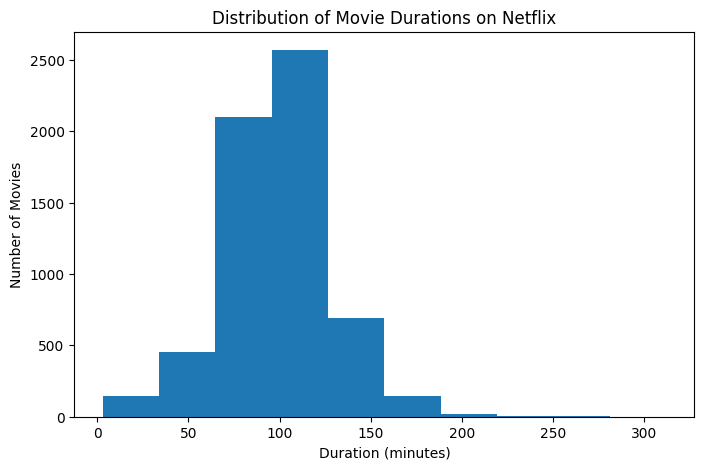

In [ ]:

# Select Movies only
movies = df[df["type"] == "Movie"]

# Display duration statistics
print("Average movie duration:", movies["duration_min"].mean().round(2), "minutes")
print("Shortest movie:", movies["duration_min"].min(), "minutes")
print("Longest movie:", movies["duration_min"].max(), "minutes")

# Create a histogram
plt.figure(figsize=(8, 5))
plt.hist(movies["duration_min"].dropna(), bins=20)

plt.title("Distribution of Movie Durations on Netflix")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.show()


###Movies vs TV Shows by Release Year.

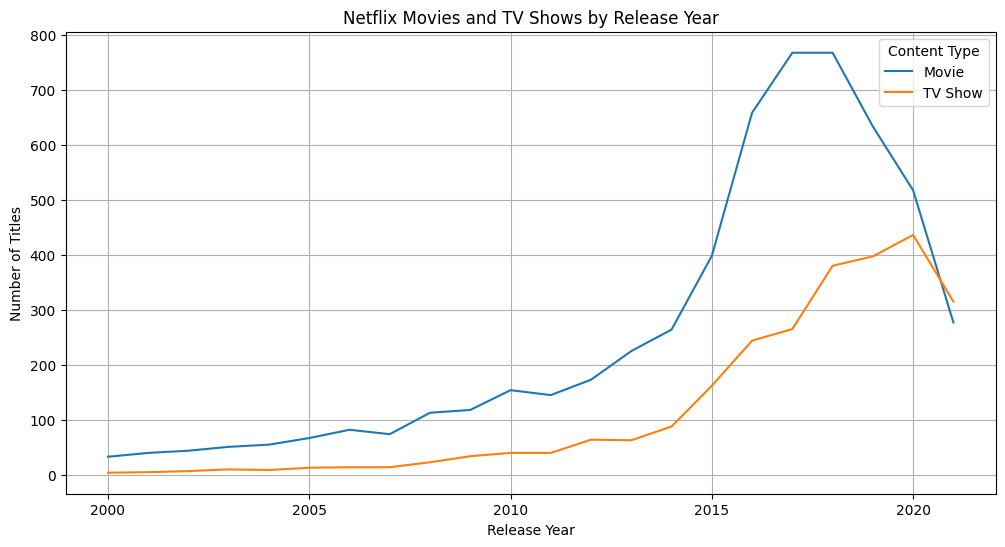

In [17]:

# Remove rows with missing release years
year_data = df.dropna(subset=["release_year"]).copy()

# Count Movies and TV Shows by release year
year_type = year_data.groupby(
    ["release_year", "type"]
).size().unstack(fill_value=0)

# Keep years from 2000 onwards
year_type = year_type[year_type.index >= 2000]

# Create a line graph
year_type.plot(kind="line", figsize=(12, 6))

plt.title("Netflix Movies and TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.grid(True)
plt.show()


###Content Ratings: Movies vs TV Shows

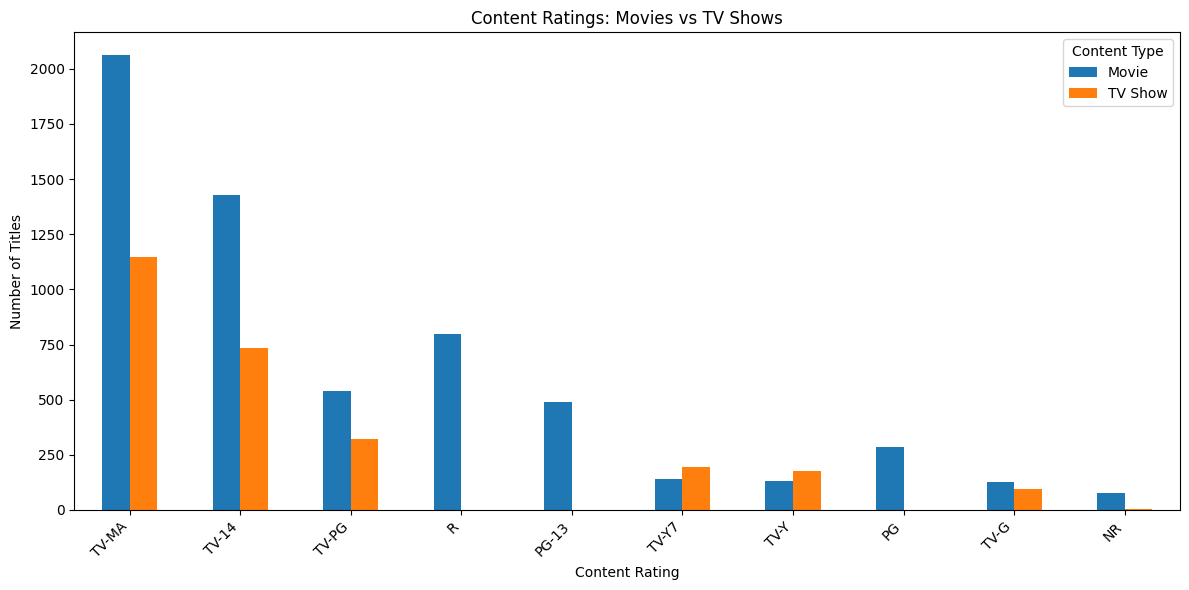

In [18]:

# Count ratings for Movies and TV Shows
rating_data = df.dropna(subset=["rating"])

rating_comparison = rating_data.groupby(
    ["rating", "type"]
).size().unstack(fill_value=0)

# Select the 10 most common ratings overall
top_ratings = rating_comparison.sum(axis=1).nlargest(10).index
rating_comparison = rating_comparison.loc[top_ratings]

# Plot both content types on the same graph
rating_comparison.plot(kind="bar", figsize=(12, 6))

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


###Netflix Content Additions by Year: Movies vs TV Shows

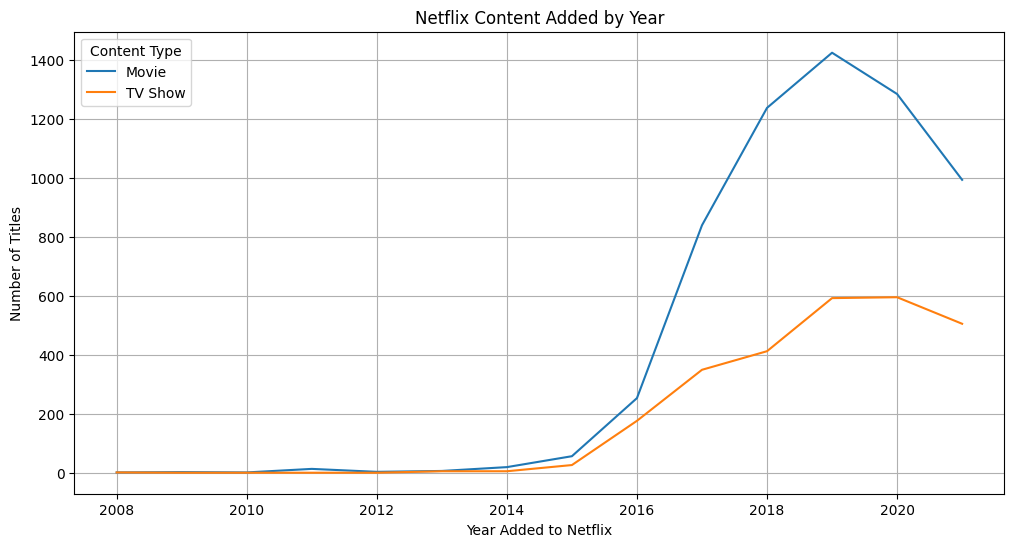

In [19]:

# Convert date_added into datetime format
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

# Extract the year Netflix added each title
df["year_added"] = df["date_added"].dt.year

# Count titles added each year by content type
added_data = df.dropna(subset=["year_added"])

added_counts = added_data.groupby(
    ["year_added", "type"]
).size().unstack(fill_value=0)

# Plot the results
added_counts.plot(kind="line", figsize=(12, 6))

plt.title("Netflix Content Added by Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.grid(True)
plt.show()


### Directors with the most titles on Netflix

Top 10 Directors with the Most Netflix Titles:
director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Martin Scorsese        12
Youssef Chahine        12
Jay Chapman            12
Name: count, dtype: int64


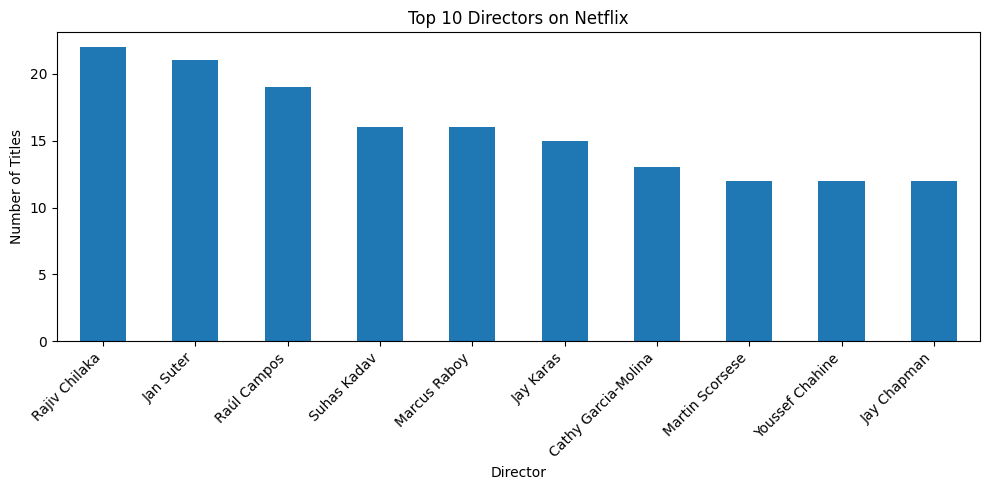

In [27]:
director_data = df[df["director"].notna()].copy()

director_data["director"] = director_data["director"].str.split(", ")
director_data = director_data.explode("director")

director_data["director"] = director_data["director"].str.strip()

director_data = director_data[
    (director_data["director"] != "") &
    (director_data["director"].str.lower() != "unknown")
]

top_directors = director_data["director"].value_counts().head(10)

print("Top 10 Directors with the Most Netflix Titles:")
print(top_directors)

top_directors.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Directors on Netflix")
plt.xlabel("Director")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Months which has the  most content added to Netflix

Netflix Content Added by Month:
type  Movie  TV Show
Jan     546      192
Feb     382      181
Mar     529      213
Apr     550      214
May     439      193
Jun     492      236
Jul     565      262
Aug     519      236
Sep     519      251
Oct     545      215
Nov     498      207
Dec     547      266


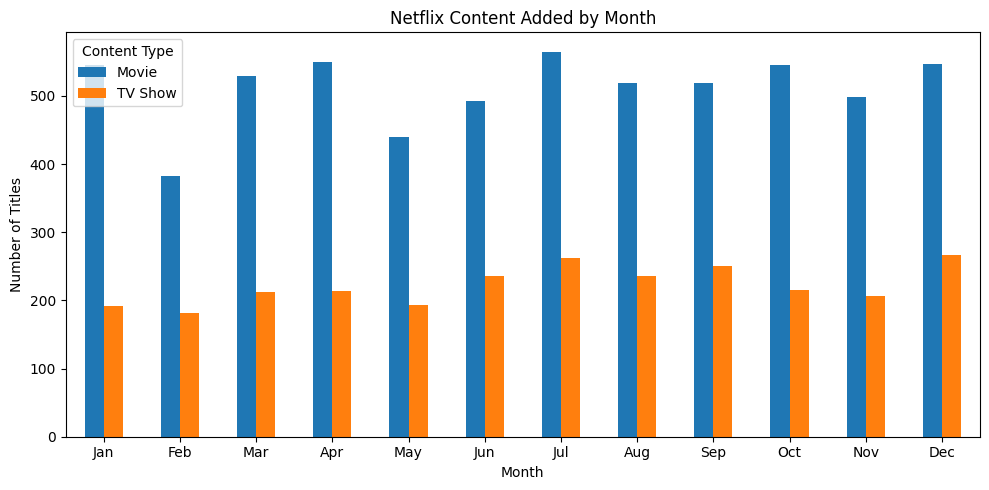

In [22]:

# Analyse Netflix content added by month

df["date_added"] = pd.to_datetime(
    df["date_added"].astype(str).str.strip(),
    errors="coerce"
)

df["month_added"] = df["date_added"].dt.month

month_data = df.dropna(subset=["month_added"]).copy()

month_type = month_data.groupby(
    ["month_added", "type"]
).size().unstack(fill_value=0)

month_type = month_type.reindex(range(1, 13), fill_value=0)

month_type.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print("Netflix Content Added by Month:")
print(month_type)

month_type.plot(kind="bar", figsize=(10, 5))

plt.title("Netflix Content Added by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


###Actors who appear in the most Netflix titles

Top 10 Actors with the Most Netflix Titles:
cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Takahiro Sakurai    32
Naseeruddin Shah    32
Rupa Bhimani        31
Om Puri             30
Akshay Kumar        30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64


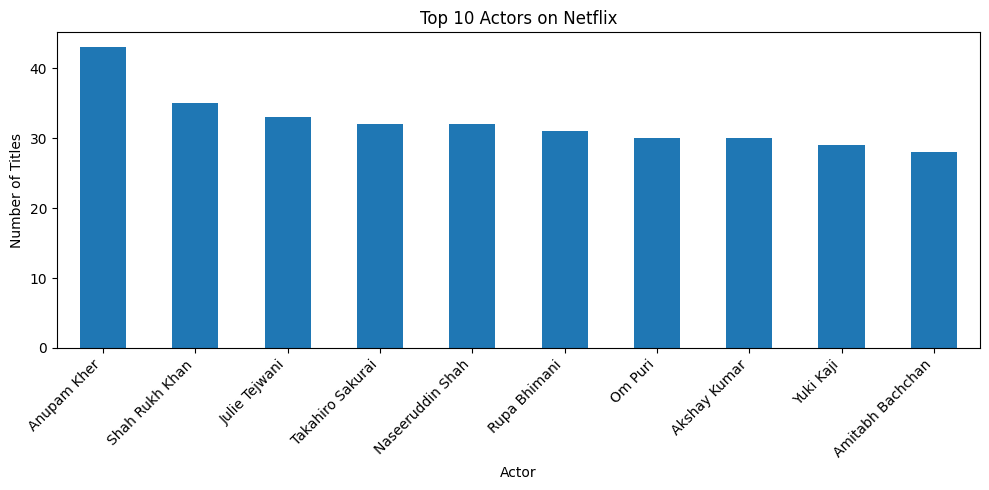

In [26]:

cast_data = df[df["cast"].notna()].copy()

cast_data["cast"] = cast_data["cast"].str.split(", ")
cast_data = cast_data.explode("cast")

cast_data["cast"] = cast_data["cast"].str.strip()

cast_data = cast_data[
    (cast_data["cast"] != "") &
    (cast_data["cast"].str.lower() != "unknown")
]

top_actors = cast_data["cast"].value_counts().head(10)

print("Top 10 Actors with the Most Netflix Titles:")
print(top_actors)

top_actors.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Actors on Netflix")
plt.xlabel("Actor")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
